In [1]:
print("Hello! Welcome to my E-commerce Data Analysis Project.")

Hello! Welcome to my E-commerce Data Analysis Project.


In [2]:
# Import libraries for our e-commerce data analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set a professional visualisation style
sns.set_theme(style="whitegrid")

# Display charts inside the notebook
%matplotlib inline

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
# Load the cleaned Excel dataset

df = pd.read_excel('/content/E-Commerce cleaned.xlsx')

# Display the first five records
df.head()

,CustomerGender,ProductName,ProductPrice,CostOfGood,ProductCategory,CustomerCountry,CustomerContinent,OrderTime,OrderDay,OrderMonth,QuantitySold,discountPerQuantity,salePrice,OrderYear
0,Female,Hat,713,249.55,Movies,Seychelles,Africa,13:43:00,1,February,3,0.09,1946.49,2017
1,Female,Cheese,60,47.40,Health,Qatar,Asia,12:25:00,11,February,5,0.02,294.00,2020
2,Male,Chips,310,145.70,Sports,Cameroon,Africa,20:14:00,25,September,2,0.03,601.40,2020
3,Female,Chair,468,149.76,Beauty,Guadeloupe,North America,13:13:00,30,June,1,0.10,421.20,2020
4,Male,Chicken,360,140.40,Health,Swaziland,Africa,22:50:00,28,September,6,0.08,1987.20,2020


In [5]:
print("Dataset size:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values in each column:")
print(df.isnull().sum())

Dataset size: (15300, 14)

Column names:
['CustomerGender', 'ProductName', 'ProductPrice', 'CostOfGood', 'ProductCategory', 'CustomerCountry', 'CustomerContinent', 'OrderTime', 'OrderDay', 'OrderMonth', 'QuantitySold', 'discountPerQuantity', 'salePrice', 'OrderYear']

Missing values in each column:
CustomerGender         0
ProductName            0
ProductPrice           0
CostOfGood             0
ProductCategory        0
CustomerCountry        0
CustomerContinent      0
OrderTime              0
OrderDay               0
OrderMonth             0
QuantitySold           0
discountPerQuantity    0
salePrice              0
OrderYear              0
dtype: int64


In [6]:
print("DATA TYPES")
print(df.dtypes)

print("\nNUMERICAL SUMMARY")
df[['ProductPrice', 'CostOfGood', 'QuantitySold',
    'discountPerQuantity', 'salePrice']].describe()

DATA TYPES
CustomerGender          object
ProductName             object
ProductPrice             int64
CostOfGood             float64
ProductCategory         object
CustomerCountry         object
CustomerContinent       object
OrderTime               object
OrderDay                 int64
OrderMonth              object
QuantitySold             int64
discountPerQuantity    float64
salePrice              float64
OrderYear                int64
dtype: object

NUMERICAL SUMMARY


,ProductPrice,CostOfGood,QuantitySold,discountPerQuantity,salePrice
count,15300.000000,15300.000000,15300.000000,15300.000000,15300.000000
mean,502.182222,262.758284,5.482353,0.055169,2603.282549
std,287.596789,186.453029,2.868404,0.028821,2166.503921
min,1.000000,0.290000,1.000000,0.010000,0.960000
25%,253.000000,112.380000,3.000000,0.030000,810.877500
50%,504.000000,224.640000,6.000000,0.060000,1984.150000
75%,750.000000,382.080000,8.000000,0.080000,3922.967500
max,1000.000000,848.300000,10.000000,0.100000,9900.000000


In [7]:
# Calculate total cost
df['Total Cost'] = df['CostOfGood'] * df['QuantitySold']

# Calculate gross profit
df['Gross Profit'] = df['salePrice'] - df['Total Cost']

# Calculate gross profit margin
df['Gross Profit Margin'] = (
    df['Gross Profit'] / df['salePrice']
) * 100

# Calculate discount amount
df['Discount Amount'] = (
    df['ProductPrice'] * df['QuantitySold'] - df['salePrice']
)

# Display the calculated results
df[['ProductName', 'salePrice', 'Total Cost',
    'Gross Profit', 'Gross Profit Margin',
    'Discount Amount']].head()

,ProductName,salePrice,Total Cost,Gross Profit,Gross Profit Margin,Discount Amount
0,Hat,1946.49,748.65,1197.84,61.538462,192.51
1,Cheese,294.00,237.00,57.00,19.387755,6.00
2,Chips,601.40,291.40,310.00,51.546392,18.60
3,Chair,421.20,149.76,271.44,64.444444,46.80
4,Chicken,1987.20,842.40,1144.80,57.608696,172.80


In [8]:
total_revenue = df['salePrice'].sum()
total_cost = df['Total Cost'].sum()
total_profit = df['Gross Profit'].sum()
total_quantity = df['QuantitySold'].sum()
overall_margin = (total_profit / total_revenue) * 100
total_discount = df['Discount Amount'].sum()

print("OVERALL BUSINESS PERFORMANCE")
print("--------------------------------")
print(f"Total Revenue: {total_revenue:,.2f}")
print(f"Total Cost: {total_cost:,.2f}")
print(f"Total Gross Profit: {total_profit:,.2f}")
print(f"Total Quantity Sold: {total_quantity:,.0f}")
print(f"Overall Gross Profit Margin: {overall_margin:.2f}%")
print(f"Total Discount Amount: {total_discount:,.2f}")

OVERALL BUSINESS PERFORMANCE
--------------------------------
Total Revenue: 39,830,223.00
Total Cost: 22,050,381.55
Total Gross Profit: 17,779,841.45
Total Quantity Sold: 83,880
Overall Gross Profit Margin: 44.64%
Total Discount Amount: 2,326,743.00


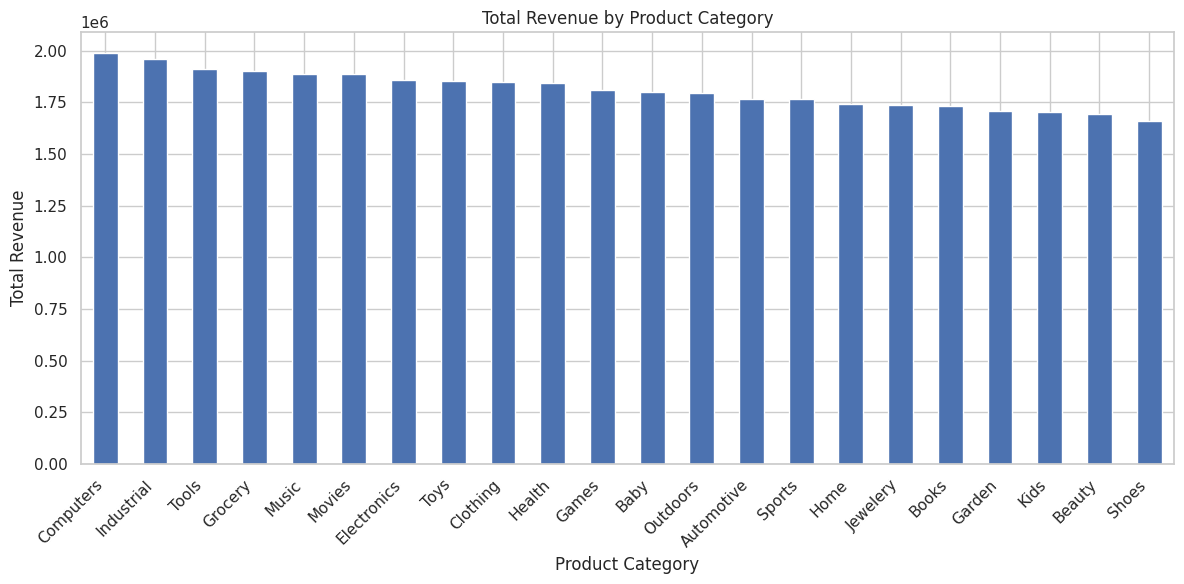

In [9]:
# Calculate revenue for each product category
category_revenue = (
    df.groupby('ProductCategory')['salePrice']
    .sum()
    .sort_values(ascending=False)
)

# Create the chart
plt.figure(figsize=(12, 6))

category_revenue.plot(
    kind='bar',
    title='Total Revenue by Product Category'
)

plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

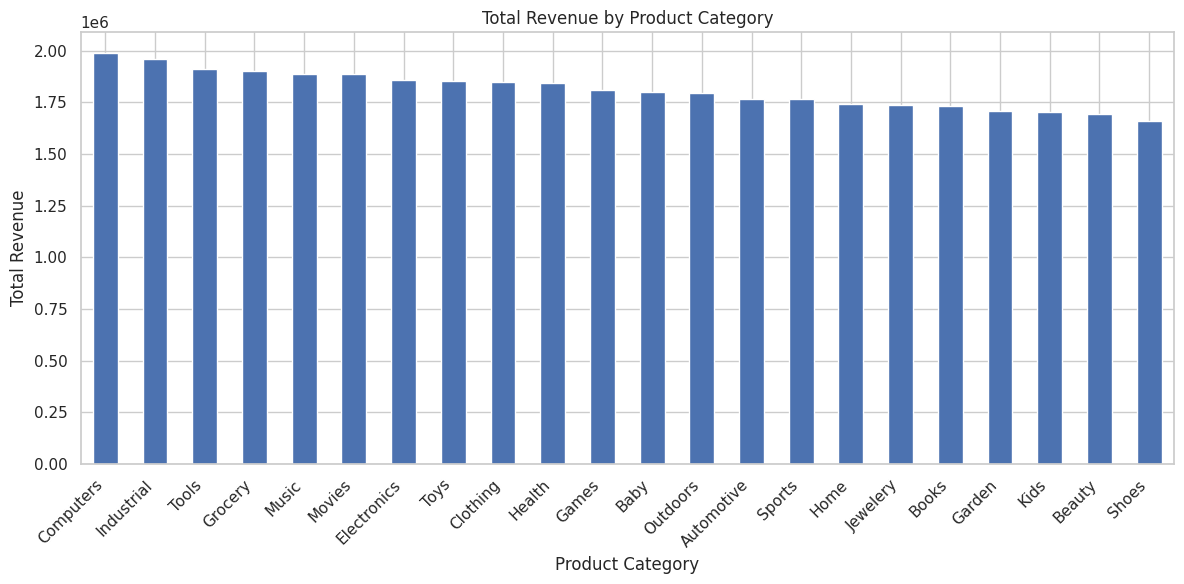

In [10]:
plt.figure(figsize=(12, 6))

category_revenue.plot(kind='bar')

plt.title('Total Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.savefig(
    'revenue_by_product_category.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

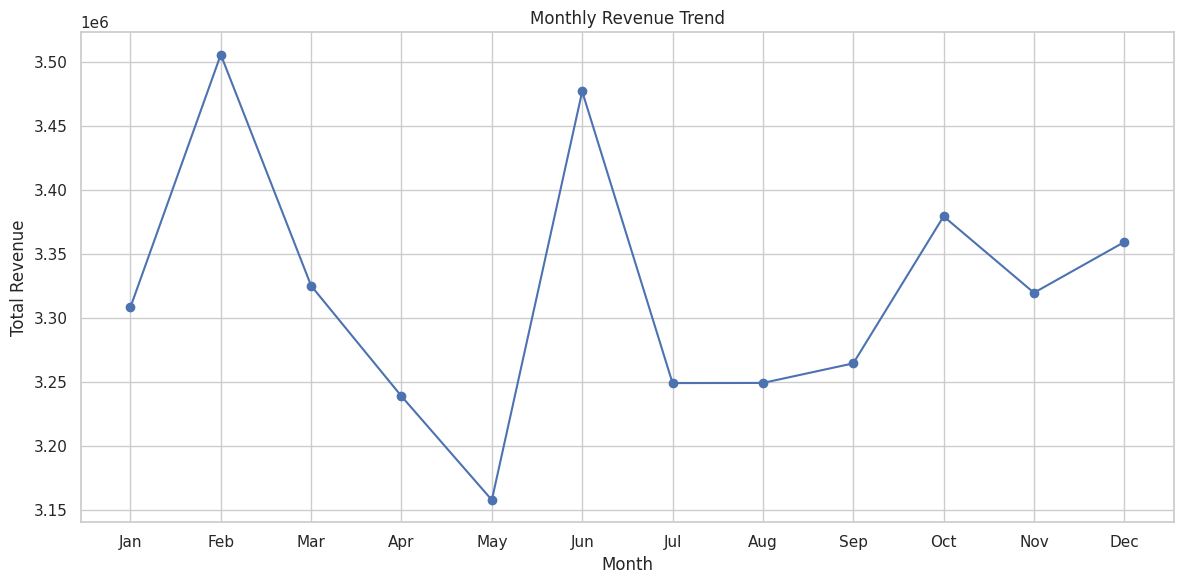

In [11]:
# Calculate revenue for each month
monthly_revenue = (
    df.groupby('OrderMonth')['salePrice']
    .sum()
)

# Arrange months in calendar order
month_order = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

monthly_revenue.index = monthly_revenue.index.str[:3]
monthly_revenue = monthly_revenue.reindex(month_order)

# Create the chart
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.grid(True)
plt.tight_layout()
plt.show()

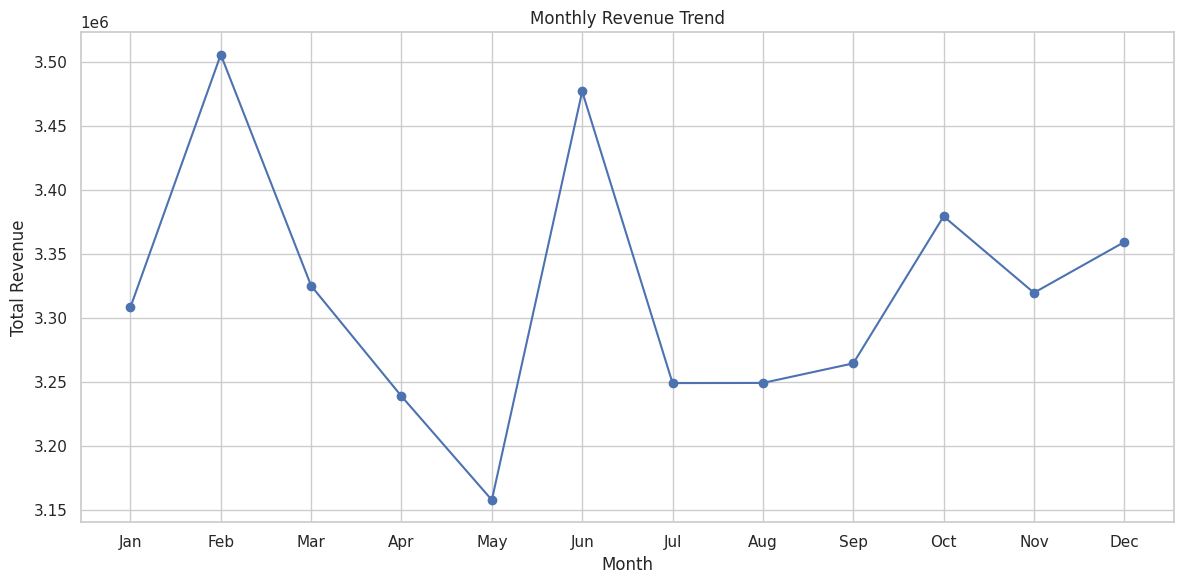

In [12]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker='o'
)

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.grid(True)
plt.tight_layout()

plt.savefig(
    'monthly_revenue_trend.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

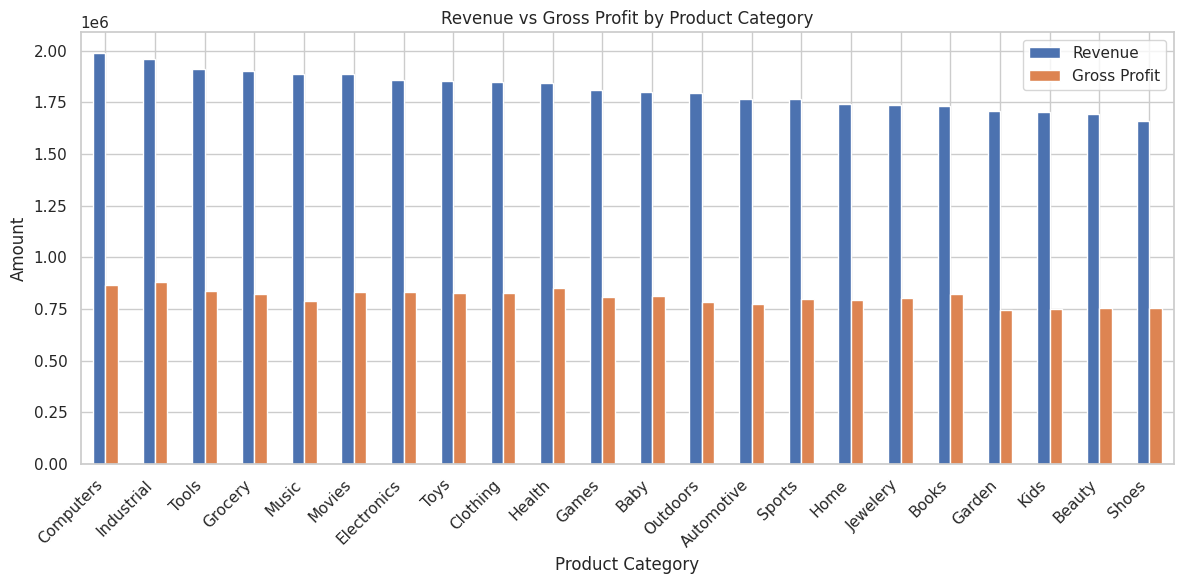

In [13]:
# Calculate revenue and gross profit by category
category_performance = df.groupby('ProductCategory').agg({
    'salePrice': 'sum',
    'Gross Profit': 'sum'
})

# Sort by revenue
category_performance = category_performance.sort_values(
    by='salePrice',
    ascending=False
)

# Create the comparison chart
category_performance.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Revenue vs Gross Profit by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Amount')
plt.xticks(rotation=45, ha='right')
plt.legend(['Revenue', 'Gross Profit'])
plt.tight_layout()
plt.show()

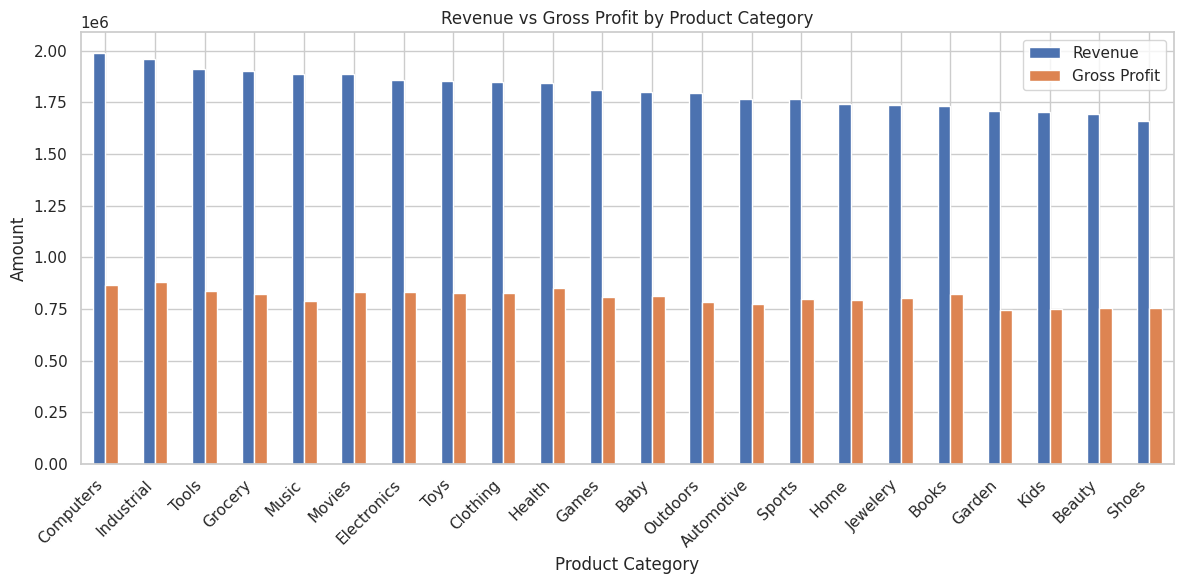

In [14]:
category_performance.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Revenue vs Gross Profit by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Amount')
plt.xticks(rotation=45, ha='right')
plt.legend(['Revenue', 'Gross Profit'])
plt.tight_layout()

plt.savefig(
    'revenue_vs_gross_profit.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

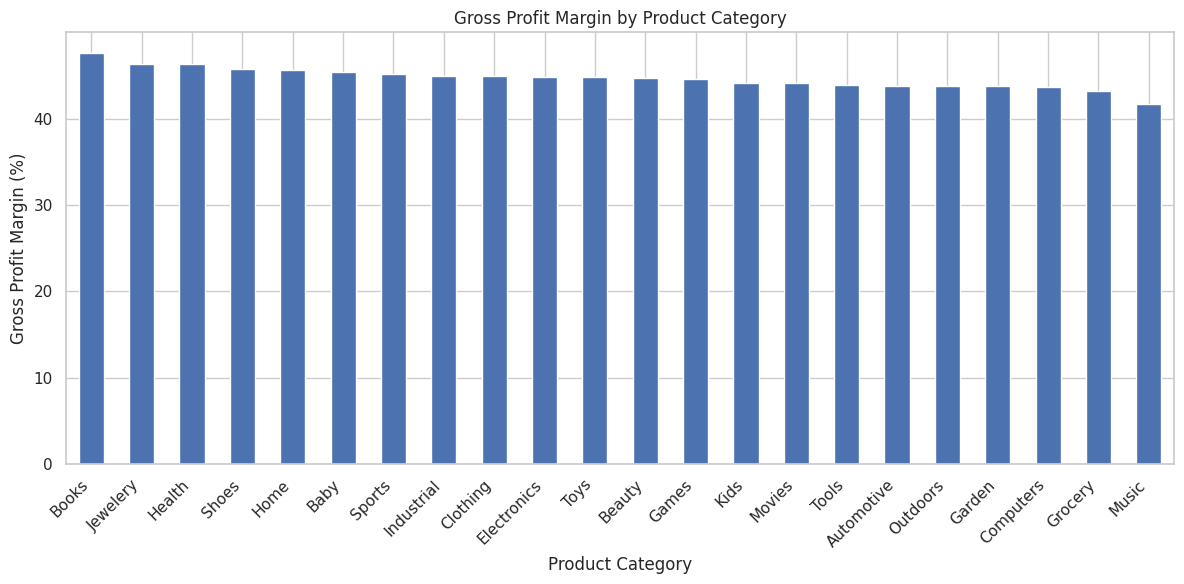

In [15]:
# Calculate gross profit margin for each category
category_margin = (
    df.groupby('ProductCategory')
    .agg({
        'Gross Profit': 'sum',
        'salePrice': 'sum'
    })
)

category_margin['Gross Profit Margin'] = (
    category_margin['Gross Profit'] /
    category_margin['salePrice']
) * 100

# Sort from highest to lowest margin
category_margin = category_margin.sort_values(
    by='Gross Profit Margin',
    ascending=False
)

# Create the chart
plt.figure(figsize=(12, 6))

category_margin['Gross Profit Margin'].plot(
    kind='bar'
)

plt.title('Gross Profit Margin by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Gross Profit Margin (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

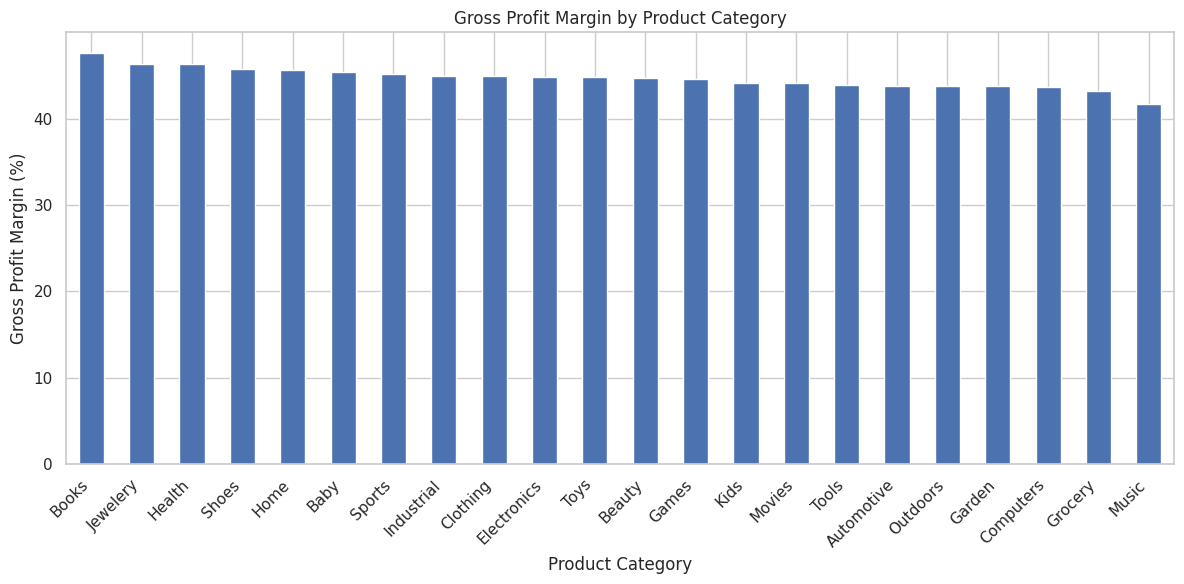

In [16]:
plt.figure(figsize=(12, 6))

category_margin['Gross Profit Margin'].plot(kind='bar')

plt.title('Gross Profit Margin by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Gross Profit Margin (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.savefig(
    'gross_profit_margin_by_category.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

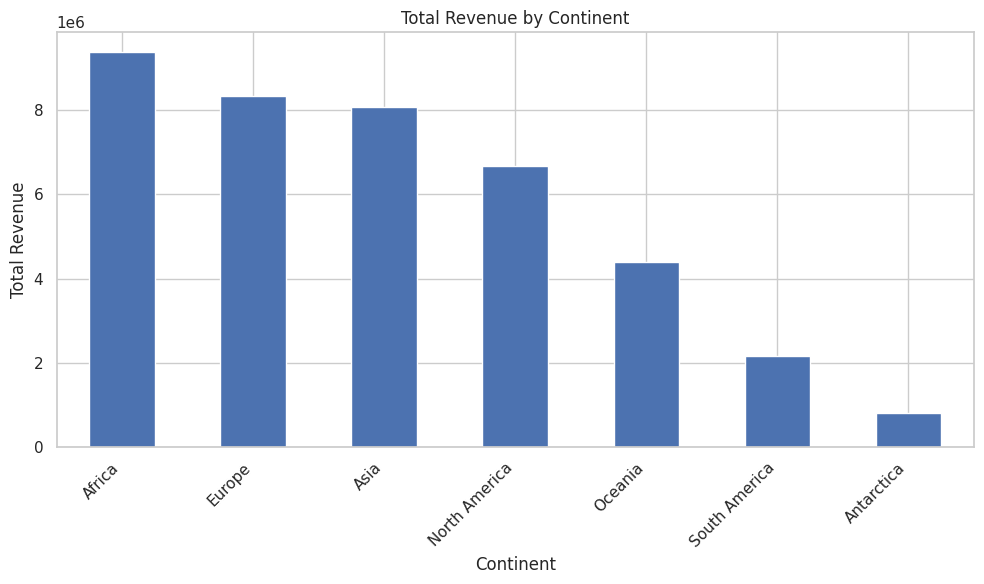

In [17]:
# Calculate revenue by continent
continent_revenue = (
    df.groupby('CustomerContinent')['salePrice']
    .sum()
    .sort_values(ascending=False)
)

# Create the chart
plt.figure(figsize=(10, 6))

continent_revenue.plot(
    kind='bar'
)

plt.title('Total Revenue by Continent')
plt.xlabel('Continent')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

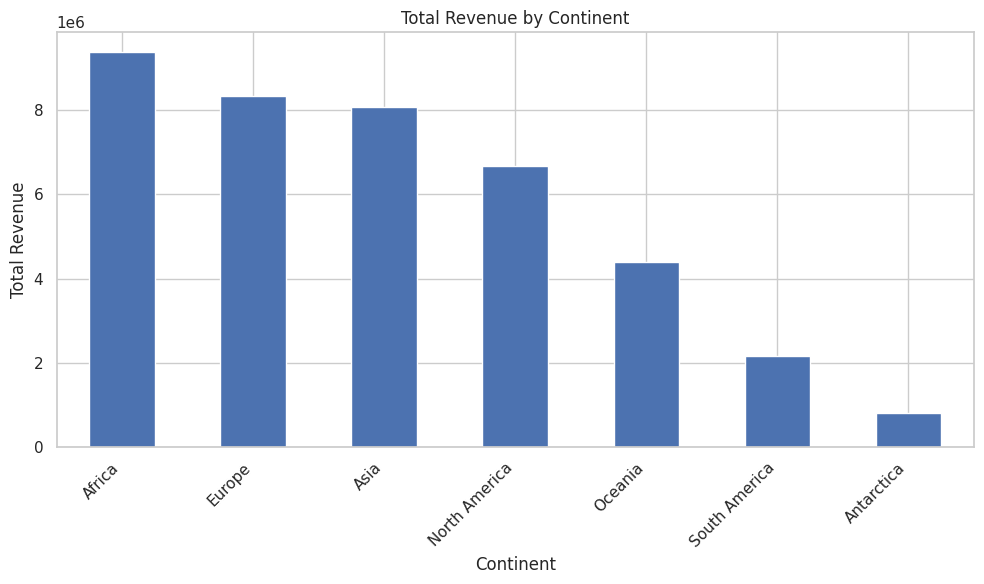

In [18]:
plt.figure(figsize=(10, 6))

continent_revenue.plot(kind='bar')

plt.title('Total Revenue by Continent')
plt.xlabel('Continent')
plt.ylabel('Total Revenue')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.savefig(
    'revenue_by_continent.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

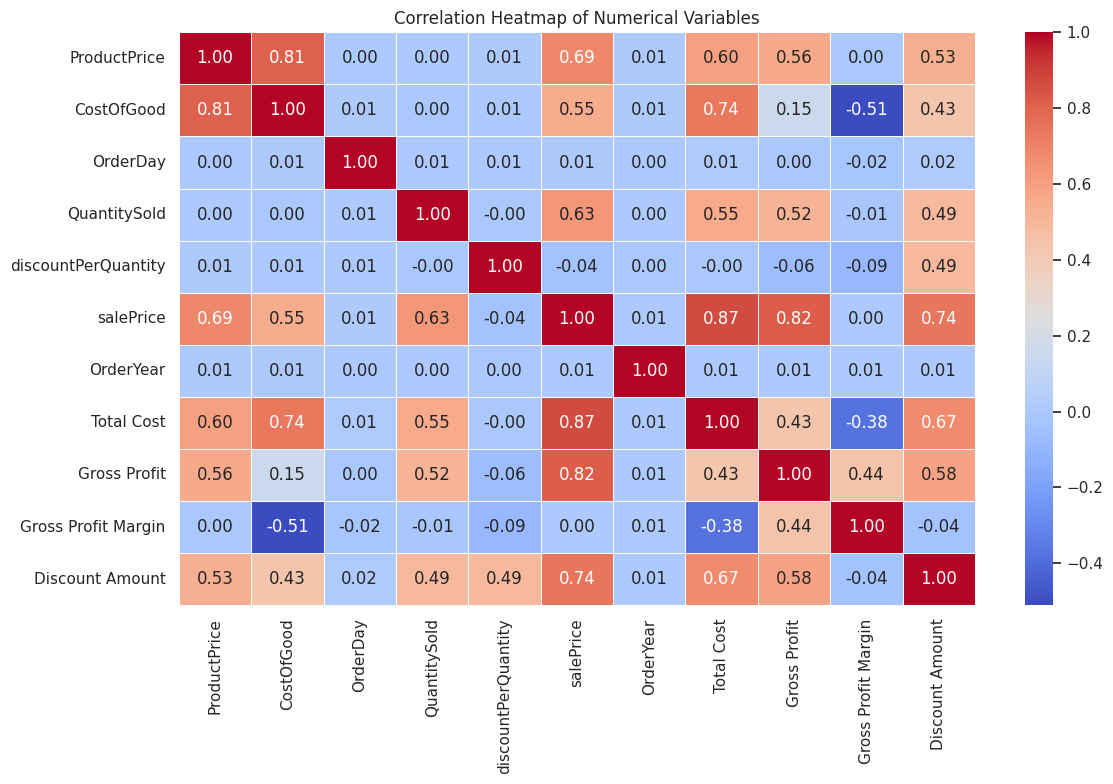

In [19]:
# Select numerical columns
numeric_data = df.select_dtypes(include=['int64', 'float64'])

# Calculate correlations
correlation_matrix = numeric_data.corr()

# Create the heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()

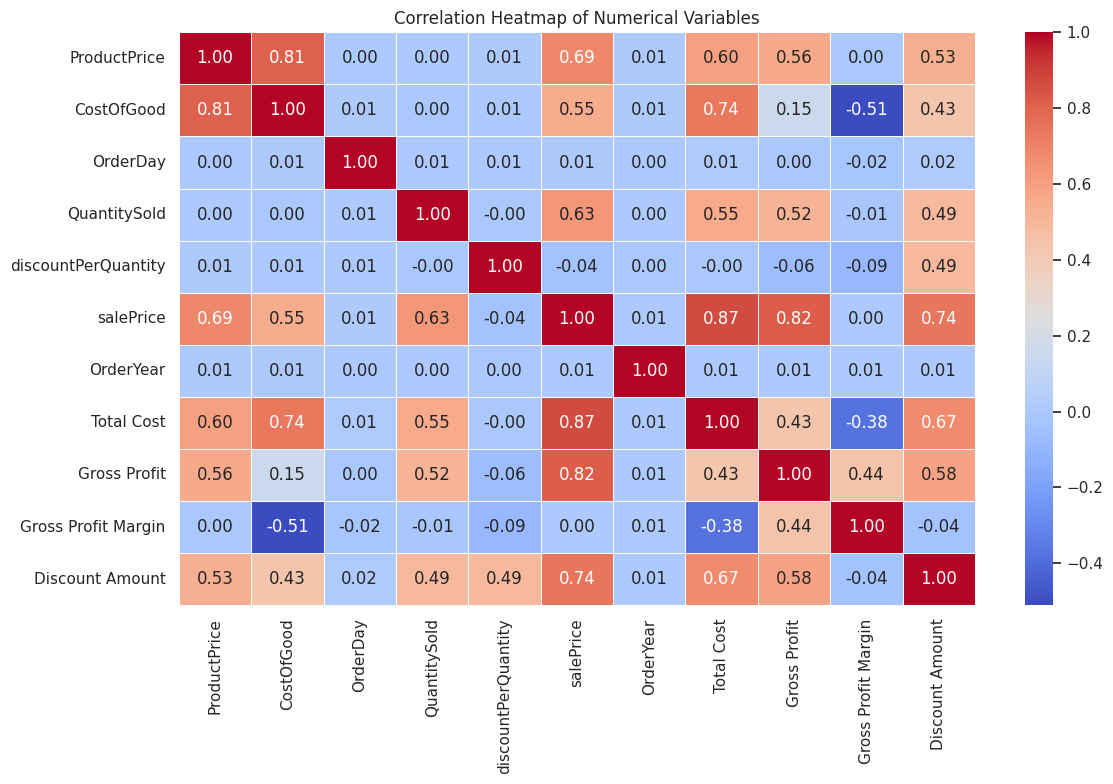

In [20]:
numeric_data = df.select_dtypes(include=['int64', 'float64'])
correlation_matrix = numeric_data.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()

plt.savefig(
    'correlation_heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [21]:
import zipfile

chart_files = [
    'revenue_by_product_category.png',
    'monthly_revenue_trend.png',
    'revenue_vs_gross_profit.png',
    'gross_profit_margin_by_category.png',
    'revenue_by_continent.png',
    'correlation_heatmap.png'
]

with zipfile.ZipFile('ecommerce_charts.zip', 'w') as zip_file:
    for chart in chart_files:
        zip_file.write(chart)

from google.colab import files
files.download('ecommerce_charts.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>